In [16]:
# Logistic Regression - Student Pass/Fail Prediction
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

In [17]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [18]:
# Step 2: Create Dataset

data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6,
                    1, 2, 3, 4, 5, 6],

    "Result": [
        "Fail", "Fail", "Fail", "Fail", "Pass", "Pass",
        "Fail", "Fail", "Fail", "Pass", "Pass", "Pass"
    ]
}

df = pd.DataFrame(data)

print("STUDENT DATASET")
print(df)

STUDENT DATASET
    Study_Hours Result
0             1   Fail
1             2   Fail
2             3   Fail
3             4   Fail
4             5   Pass
5             6   Pass
6             1   Fail
7             2   Fail
8             3   Fail
9             4   Pass
10            5   Pass
11            6   Pass


In [19]:
# Step 3: Separate Input and Output

X = df[["Study_Hours"]]
y = df["Result"]


In [20]:
# Step 4: Split Dataset into Training and Testing Data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))



Training Records: 9
Testing Records: 3


In [21]:
# Step 5: Create Logistic Regression Model

model = LogisticRegression()

In [22]:
# Step 6: Train the Model

model.fit(X_train, y_train)

print("\nModel Trained Successfully!")



Model Trained Successfully!


In [23]:
# Step 7: Display Learned Coefficients

print("\nLEARNED MODEL PARAMETERS")

print("Intercept:", model.intercept_[0])
print("Coefficient:", model.coef_[0][0])


LEARNED MODEL PARAMETERS
Intercept: -4.67287814115274
Coefficient: 1.3248119801450653


In [24]:

y_pred = model.predict(X_test)

print("\nACTUAL RESULTS:")
print(y_test.values)

print("\nPREDICTED RESULTS:")
print(y_pred)



ACTUAL RESULTS:
['Pass' 'Fail' 'Fail']

PREDICTED RESULTS:
['Pass' 'Fail' 'Pass']


In [25]:
# Step 9: Calculate Prediction Probabilities

y_prob = model.predict_proba(X_test)

print("\nPREDICTED PROBABILITIES:")
print(y_prob)


PREDICTED PROBABILITIES:
[[0.03640399 0.96359601]
 [0.6678423  0.3321577 ]
 [0.34833413 0.65166587]]


In [26]:
comparison = pd.DataFrame({
    "Study_Hours": X_test["Study_Hours"].values,
    "Actual_Result": y_test.values,
    "Predicted_Result": y_pred
})

print("\nACTUAL VS PREDICTED RESULTS")
print(comparison)



ACTUAL VS PREDICTED RESULTS
   Study_Hours Actual_Result Predicted_Result
0            6          Pass             Pass
1            3          Fail             Fail
2            4          Fail             Pass


In [27]:

study_hours = np.linspace(
    df["Study_Hours"].min(),
    df["Study_Hours"].max(),
    200
).reshape(-1, 1)


In [28]:
pass_index = list(model.classes_).index("Pass")

In [29]:
probabilities = model.predict_proba(study_hours)[:, pass_index]

plt.figure(figsize=(9, 5))

C:\Users\deeks\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


<Figure size 900x500 with 0 Axes>

<Figure size 900x500 with 0 Axes>

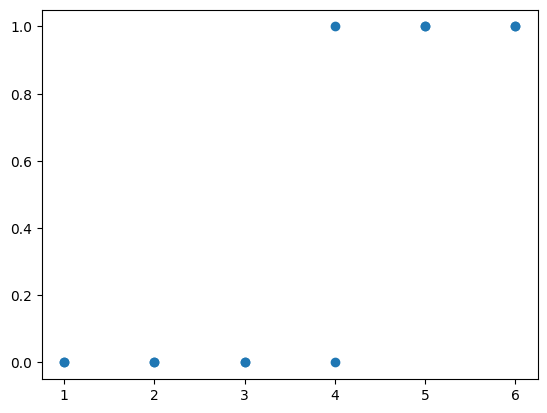

In [30]:

plt.scatter(
    df["Study_Hours"],
    df["Result"].map({"Fail": 0, "Pass": 1}),
    label="Actual Results"
)

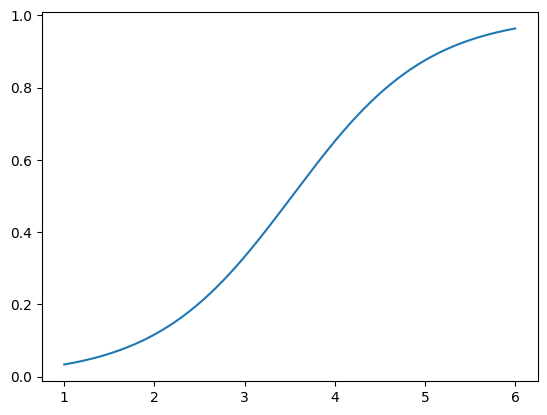

In [31]:

plt.plot(
    study_hours,
    probabilities,
    label="Logistic Regression Curve"
)

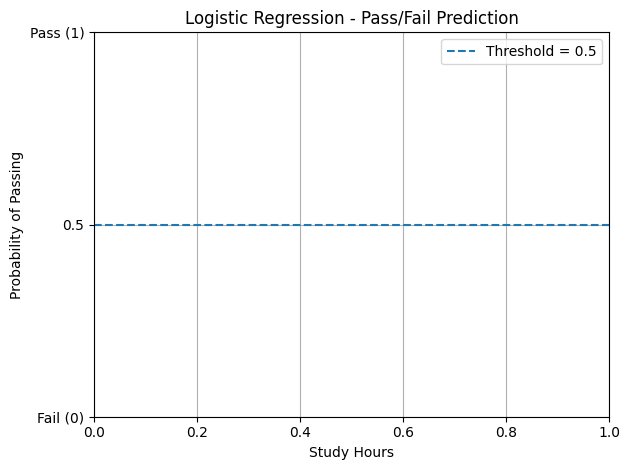

In [32]:
plt.axhline(
    y=0.5,
    linestyle="--",
    label="Threshold = 0.5"
)

plt.xlabel("Study Hours")
plt.ylabel("Probability of Passing")
plt.title("Logistic Regression - Pass/Fail Prediction")

plt.yticks(
    [0, 0.5, 1],
    ["Fail (0)", "0.5", "Pass (1)"]
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [33]:

accuracy = accuracy_score(y_test, y_pred)

print("\nMODEL EVALUATION METRICS")

print("Accuracy:", accuracy * 100, "%")



MODEL EVALUATION METRICS
Accuracy: 66.66666666666666 %
